# Vizualisação de um Buraco Negro


* PET - Física
* Petiano: Wallysson Pereira da Silva
* Data: 03/02/2025

$\quad$ Resumminho papapa

## Importando bibliotecas

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import time

## Informações sobre as bibliotecas

In [2]:
%load_ext version_information
%version_information Matplotlib, Numpy

Software versions
Python 3.12.7 64bit [MSC v.1929 64 bit (AMD64)]
IPython 8.29.0
OS Windows 11 10.0.26200 SP0
Matplotlib 3.9.2
Numpy 2.1.3
Wed Aug 12 09:50:50 2026 Hora oficial do Brasil

## 1. O Conceito de Buraco Negro

$\quad$ Os buracos negros são uns dos objetivos mais integrantes da física.

O conceito mundano de que um buraco negro é "um objeto tão massivo que nem a luz consegue escapar dele" na verdade teve sua primeira aparição muito antes da Relatividade Geral. Em XXXX o Físico TAL utilizou o cunhou o conceito de uma "estrela negra" para idealizar uma estrela tão massiva que a sua velocidade de escape acaba sendo maior do que a velocidade da luz.  

No entanto, a aparição do conceito de buraco negro ao qual estamos acostumados só foi aparecer em 1915, quando Karl Schwarzschild resolveu as Equações de Campo de Einstein pro vácuo.  


Há não muito tempo atrás, em 2019, esses objetos foram finalmente observados, numa colaboração gigantes realizada pelo Event Horizon Telescope para a observação do buraco negro M87* 

Um dos primeiros trabalhos do imageamento de buracos negros vêm de Luminet, com a introdução do Ray-Tracing algorithm

Conceito de ISCO e a sombra do buraco negro





Durante este `Notebook` iremos revisar os conceitos relativísticos necessários, porém de maneira não tão aprofundada. 



Lentes gravitacionais.


A expressão geral para o elemento de linha é 
$$
ds^2 = g_{\mu \nu }dx^{\mu}dx^{\nu}
$$
Impondo a condição de que queremos um conjunto de coordenadas $x^{\mu}$ no qual a métrica é esfericamente simétrica e estacionária, a obtenção da seguinte expressão é natural
$$
ds^2 = -(1-\frac{R_s}{r})dt^2 + (1-\frac{R_s}{r})^{-1}dr^2 + r^2d\theta^2 + r^2\sin^2(\theta)d\phi^2,
$$
onde $R_s = \frac{2GM}{c^2}$ é o chamado raio de Schwarzschild.



Equação da trajetória do fóton
$$
\frac{d^2u}{d\phi^2} + u = \frac{3}{2}R_s u^2,
$$
onde $u = \frac{1}{r}$. Forma de uma Equação de Binet.


## 2. Ray-Tracing para a = 0

Definindo funções importantes.

In [2]:
# --- 1. PARÂMETROS E FUNÇÕES FÍSICAS ---
M = 1.0
a = 0.0
bc = (3 * np.sqrt(3) * M) / ((1 - a)**(3/2))
horizon = 2 * M / (1 - a)
photon_sphere = 3 * M

# --- 2. INTEGRAÇÃO RK4 (EQUAÇÃO DE BINET) ---
def rk4_binet(u, du, dphi, a):
    # Equação diferencial de segunda ordem: u'' = 3Mu^2 - (1-a)u
    def f_du(u_val):
        return 3 * M * u_val**2 - (1 - a) * u_val

    k1_u = du
    k1_du = f_du(u)
    
    k2_u = du + 0.5 * dphi * k1_du
    k2_du = f_du(u + 0.5 * dphi * k1_u)
    
    k3_u = du + 0.5 * dphi * k2_du
    k3_du = f_du(u + 0.5 * dphi * k2_u)
    
    k4_u = du + dphi * k3_du
    k4_du = f_du(u + dphi * k3_u)
    
    u_new = u + (dphi / 6.0) * (k1_u + 2 * k2_u + 2 * k3_u + k4_u)
    du_new = du + (dphi / 6.0) * (k1_du + 2 * k2_du + 2 * k3_du + k4_du)
    
    return u_new, du_new



Condições Iniciais


In [9]:
# --- 3. CONDIÇÕES INICIAIS ---
r0 = 100 * M
dphi = 0.0005  # Passo angular muito fino para trajetórias ultra-suaves

# Amostragem inteligente: focando nos limites ao redor da órbita crítica
b_values = list(np.linspace(0.1, 0.98*bc, 30)) + [bc] + list(np.linspace(1.02*bc, 2.0*bc, 30))

Simulação

100%|██████████| 61/61 [00:02<00:00, 21.19it/s] 


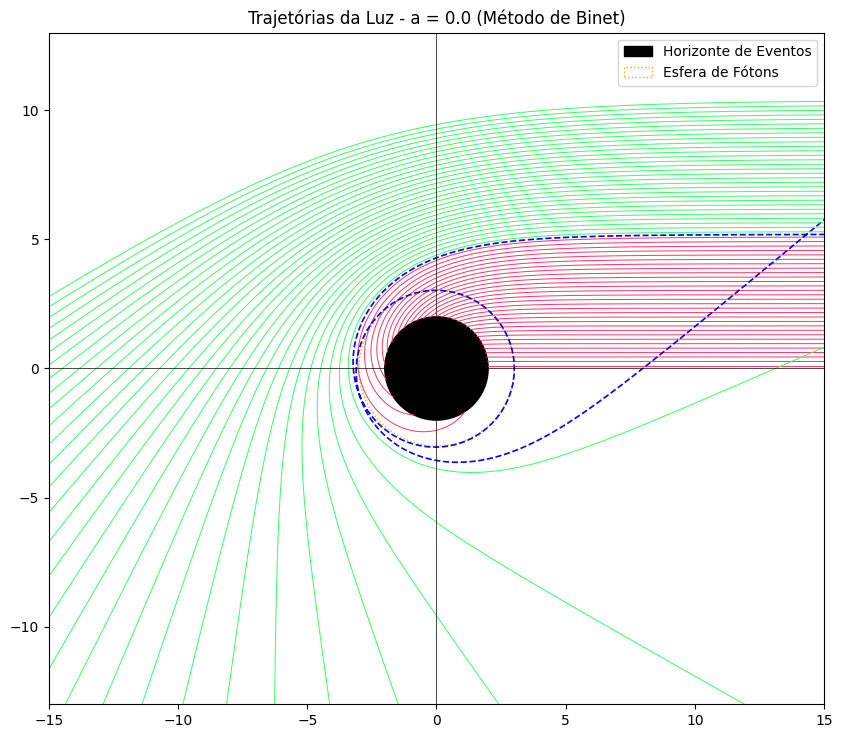

In [10]:
plt.figure(figsize=(10, 10))

# --- 4. LOOP PRINCIPAL ---
for b in tqdm(b_values):
    phi0 = np.arcsin(b / r0)
    
    # Variáveis iniciais baseadas no espaço plano infinito: u = 1/r
    current_u = 1.0 / r0
    current_du = np.cos(phi0) / b
    current_phi = phi0
    
    us, phis = [current_u], [current_phi]
    
    for _ in range(100000):
        current_u, current_du = rk4_binet(current_u, current_du, dphi, a)
        current_phi += dphi
        
        # Condição de captura (cruzou o horizonte de eventos)
        if current_u > 1.0 / horizon:
            us.append(current_u)
            phis.append(current_phi)
            break
            
        # Condição de escape (afastou-se do buraco negro na trajetória de saída)
        if current_u < 1.0 / (1.2 * r0) and current_phi > np.pi/2:
            us.append(current_u)
            phis.append(current_phi)
            break
            
        us.append(current_u)
        phis.append(current_phi)
            
    # Conversão de volta para r e depois para cartesianas
    rs = [1.0 / u for u in us]
    xs = [r * np.cos(phi) for r, phi in zip(rs, phis)]
    ys = [r * np.sin(phi) for r, phi in zip(rs, phis)]

    # Plotando com base no parâmetro de impacto
    if b < bc:
        plt.plot(xs, ys, '#FF3366', linewidth=0.7)
    elif np.isclose(b, bc):
        plt.plot(xs, ys, 'blue', linewidth=1.2, linestyle='--')
    else:
        plt.plot(xs, ys, '#33FF66', linewidth=0.7)

# --- 5. DESENHO DOS ELEMENTOS GRÁFICOS ---
black_hole = plt.Circle((0, 0), horizon, color='black', label='Horizonte de Eventos')
ps_circle = plt.Circle((0, 0), photon_sphere, color='orange', fill=False, linestyle=':', label='Esfera de Fótons')

plt.gca().add_patch(black_hole)
plt.gca().add_patch(ps_circle)

plt.xlim(-15, 15)
plt.ylim(-13, 13)
plt.gca().set_aspect('equal')
plt.legend(loc='upper right')
plt.title(f'Trajetórias da Luz - a = {a} (Método de Binet)')
plt.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
plt.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
plt.savefig('Trajetorias_Suaves.jpg', dpi=300)
plt.show()

Aparentemente é a forma correta


## Imagem primária e secundária  

<>:210: SyntaxWarning: invalid escape sequence '\c'
<>:210: SyntaxWarning: invalid escape sequence '\c'
C:\Users\noky2\AppData\Local\Temp\ipykernel_8760\1188167657.py:210: SyntaxWarning: invalid escape sequence '\c'
  ax.set_title(f'Ray-Tracing Reverso: a={a_string}, $\\theta_0$={theta_deg}$^\circ$', fontsize=11, pad=10)


1. Configurando Câmera e Parâmetros Físicos...

6. Renderizando Gráficos...

--- Processando theta_obs = 15° ---
Integração concluída em 36.14 segundos.

--- Processando theta_obs = 45° ---
Integração concluída em 38.48 segundos.

--- Processando theta_obs = 75° ---
Integração concluída em 37.09 segundos.


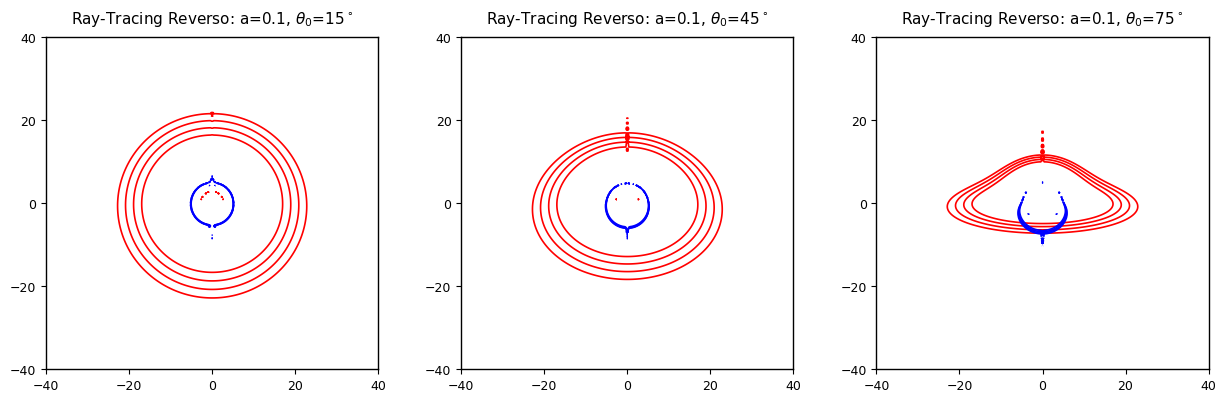


 Renderização finalizada com sucesso absoluto!


In [15]:
import numpy as np
import matplotlib.pyplot as plt
import time

# ==============================================================================
# PASSO 1: DEFINIR A CÂMERA E O ESPAÇO-TEMPO
# ==============================================================================
print("1. Configurando Câmera e Parâmetros Físicos...")

M = 1.0          # Massa do Buraco Negro
a_string = 0.1   # Parâmetro da métrica de nuvem de cordas (0.0 para Schwarzschild puro)

# Posição do Observador (Coordenadas Esféricas)
r_obs = 100.0 * M                    # Distância do observador (assintoticamente plano)
phi_obs = 0.0                        # Azimute do observador
angles_deg = [15, 45, 75]            # Ângulos de inclinação theta_obs a simular

# Campo de Visão e Resolução da Câmera
fov_size = 40.0                      # Tamanho da janela no plano da imagem [-40, 40]M
res = 300                            # Resolução (400x400 pixels)

# Níveis iso-radiais do disco
levels_primary = [16, 18, 20, 22]
levels_secondary = [10, 12, 14, 16]

# Função métrica f(r) da nuvem de cordas / Schwarzschild
def f_metric(r):
    return 1.0 - (1.0 - a_string) * (2.0 * M) / r

def df_dr_metric(r):
    return (1.0 - a_string) * (2.0 * M) / (r**2)

# Horizonte de eventos
r_horizon = (1.0 - a_string) * 2.0 * M

# ==============================================================================
# PASSO 2, 3, 4 & 5: RAY-TRACING REVERSO E CAPTURA DOS CRUZAMENTOS
# ==============================================================================
def ray_trace_camera(theta_obs_deg):
    theta_obs = np.radians(theta_obs_deg)
    print(f"\n--- Processando theta_obs = {theta_obs_deg}° ---")
    
    # 2. Configuração dos Pixels da Câmera (Plano da Imagem)
    x = np.linspace(-fov_size, fov_size, res)
    y = np.linspace(-fov_size, fov_size, res)
    X, Y = np.meshgrid(x, y)
    
    # Momento inicial dos raios emitidos para trás (Tetrad do Observador)
    # X = movimento horizontal (direção phi)
    # Y = movimento vertical (direção theta)
    p_phi = X * np.sin(theta_obs)
    p_theta = -Y
    
    # Momento radial inicial (indo em direção ao buraco negro, pr < 0)
    b_sq = X**2 + Y**2
    f_obs = f_metric(r_obs)
    p_r = - (1.0 / f_obs) * np.sqrt(np.maximum(0.0, 1.0 - f_obs * (b_sq / r_obs**2)))
    
    # Estado inicial de todos os raios na câmera (Matrizes 2D)
    r = np.full((res, res), r_obs)
    theta = np.full((res, res), theta_obs)
    phi = np.full((res, res), phi_obs)
    pr = p_r
    ptheta = p_theta
    pphi = p_phi
    
    # Matrizes para registrar o raio de interseção r_disk com o plano equatorial (theta = pi/2)
    R_primary = np.full((res, res), np.nan)
    R_secondary = np.full((res, res), np.nan)
    
    # Contador de cruzamentos do plano equatorial por pixel
    crossing_count = np.zeros((res, res), dtype=int)
    
    # Filtro de raios ativos (1 = integrando, 0 = finalizado)
    active = np.ones((res, res), dtype=bool)
    
    # Passo de integração do tempo afim (d_lambda)
    d_lambda = 0.20
    max_steps = 3000
    
    # 3. Integração Geodésica Vetorizada (Runge-Kutta 4ª Ordem)
    start_time = time.time()
    
    for step in range(max_steps):
        if not np.any(active):
            break
            
        theta_old = theta.copy()
        r_old = r.copy()
        
        # --- Passo de Integração RK4 ---
        def derivatives(curr_r, curr_th, curr_pr, curr_pth, curr_pph):
            f_r = f_metric(curr_r)
            df_r = df_dr_metric(curr_r)
            
            sin_th = np.sin(curr_th)
            # Quadrado do seno estritamente positivo para dph
            sin_th_sq = np.maximum(1e-12, sin_th**2)
            
            dr = f_r * curr_pr
            dth = curr_pth / (curr_r**2)
            dph = curr_pph / (curr_r**2 * sin_th_sq)
            
            # =================================================================
            # CORREÇÃO 1: ESTABILIZAÇÃO RADIAL EXATA
            # =================================================================
            # Pela simetria esférica, L^2 = (pth**2 + pph**2 / sin_th**2) é 
            # constante e perfeitamente igual a b_sq (X**2 + Y**2).
            # Substituir esse termo blinda a equação radial contra os pólos!
            dpr = -0.5 * df_r * (curr_pr**2) + b_sq / (curr_r**3) - df_r / (2.0 * f_r**2 + 1e-12)
            
            # =================================================================
            # CORREÇÃO 2: REGULARIZAÇÃO POLAR SIMÉTRICA (dpth)
            # =================================================================
            # Removemos o "+ 1e-8" no denominador assinado para evitar zeros falsos.
            # Usamos a técnica N * D / (D^2 + eps), que aproxima N/D perfeitamente,
            # preserva o sinal negativo quando theta cruza o pólo, e zera suavemente
            # bem no centro da singularidade.
            num_dpth = curr_pph**2 * np.cos(curr_th)
            den_dpth = curr_r**2 * (sin_th**3)
            dpth = (num_dpth * den_dpth) / (den_dpth**2 + 1e-25)
            
            dpph = np.zeros_like(curr_pph) # p_phi é conservado
            
            return dr, dth, dph, dpr, dpth, dpph

        # RK4 Etapas
        k1_r, k1_th, k1_ph, k1_pr, k1_pth, k1_pph = derivatives(r, theta, pr, ptheta, pphi)
        
        r_m = r + 0.5 * d_lambda * k1_r
        th_m = theta + 0.5 * d_lambda * k1_th
        pr_m = pr + 0.5 * d_lambda * k1_pr
        pth_m = ptheta + 0.5 * d_lambda * k1_pth
        pph_m = pphi + 0.5 * d_lambda * k1_pph
        k2_r, k2_th, k2_ph, k2_pr, k2_pth, k2_pph = derivatives(r_m, th_m, pr_m, pth_m, pph_m)
        
        r_m = r + 0.5 * d_lambda * k2_r
        th_m = theta + 0.5 * d_lambda * k2_th
        pr_m = pr + 0.5 * d_lambda * k2_pr
        pth_m = ptheta + 0.5 * d_lambda * k2_pth
        pph_m = pphi + 0.5 * d_lambda * k2_pph
        k3_r, k3_th, k3_ph, k3_pr, k3_pth, k3_pph = derivatives(r_m, th_m, pr_m, pth_m, pph_m)
        
        r_e = r + d_lambda * k3_r
        th_e = theta + d_lambda * k3_th
        pr_e = pr + d_lambda * k3_pr
        pth_e = ptheta + d_lambda * k3_pth
        pph_e = pphi + d_lambda * k3_pph
        k4_r, k4_th, k4_ph, k4_pr, k4_pth, k4_pph = derivatives(r_e, th_e, pr_e, pth_e, pph_e)
        
        # Atualiza o estado apenas dos raios ativos
        r[active] += (d_lambda / 6.0) * (k1_r + 2*k2_r + 2*k3_r + k4_r)[active]
        theta[active] += (d_lambda / 6.0) * (k1_th + 2*k2_th + 2*k3_th + k4_th)[active]
        phi[active] += (d_lambda / 6.0) * (k1_ph + 2*k2_ph + 2*k3_ph + k4_ph)[active]
        pr[active] += (d_lambda / 6.0) * (k1_pr + 2*k2_pr + 2*k3_pr + k4_pr)[active]
        ptheta[active] += (d_lambda / 6.0) * (k1_pth + 2*k2_pth + 2*k3_pth + k4_pth)[active]
        pphi[active] += (d_lambda / 6.0) * (k1_pph + 2*k2_pph + 2*k3_pph + k4_pph)[active]

        # --- 4 & 5. Detecção de Cruzamento do Plano Equatorial (theta = pi/2) ---
        # Houve cruzamento se cos(theta_old) e cos(theta) tiverem sinais opostos
        crossed = active & ((np.cos(theta_old) * np.cos(theta)) <= 0.0)
        
        if np.any(crossed):
            # Interpolação linear para achar o raio exato em que theta = pi/2
            frac = np.abs(np.cos(theta_old)) / (np.abs(np.cos(theta_old)) + np.abs(np.cos(theta)) + 1e-12)
            r_cross = r_old + frac * (r - r_old)
            
            # Atualiza o número de cruzamentos
            crossing_count[crossed] += 1
            
            # 1º Cruzamento -> Imagem Primária
            mask_p = crossed & (crossing_count == 1)
            R_primary[mask_p] = r_cross[mask_p]
            
            # 2º Cruzamento -> Imagem Secundária
            mask_s = crossed & (crossing_count == 2)
            R_secondary[mask_s] = r_cross[mask_s]
            
        # Condições de Término
        fell_in = active & (r <= (r_horizon + 1e-2))   # Sombra do buraco negro
        escaped = active & (r >= (r_obs + 10.0))       # Escapou para o infinito
        max_cross = active & (crossing_count >= 2)     # Já capturou as 2 imagens desejadas
        
        active[fell_in | escaped | max_cross] = False

    print(f"Integração concluída em {time.time() - start_time:.2f} segundos.")
    return X, Y, R_primary, R_secondary

# ==============================================================================
# PASSO 6: RENDERIZAR E EXIBIR A IMAGEM
# ==============================================================================
print("\n6. Renderizando Gráficos...")

fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))
plt.subplots_adjust(wspace=0.25)

for ax, theta_deg in zip(axes, angles_deg):
    X, Y, R_primary, R_secondary = ray_trace_camera(theta_deg)
    
    # Desenha a Imagem Primária (Vermelho)
    ax.contour(X, Y, R_primary, levels=levels_primary, colors='red', linewidths=1.2, linestyles='solid')
    
    # Desenha a Imagem Secundária (Azul)
    ax.contour(X, Y, R_secondary, levels=levels_secondary, colors='blue', linewidths=1.2, linestyles='solid')
    
    # Formatação Visual
    ax.set_xlim(-fov_size, fov_size)
    ax.set_ylim(-fov_size, fov_size)
    ax.set_aspect('equal')
    ax.set_title(f'Ray-Tracing Reverso: a={a_string}, $\\theta_0$={theta_deg}$^\circ$', fontsize=11, pad=10)
    
    ticks = [-40, -20, 0, 20, 40]
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.tick_params(axis='both', which='major', labelsize=9)
    
    for spine in ax.spines.values():
        spine.set_color('black')
        spine.set_linewidth(1.0)

plt.savefig('RayTracing_Reverso_Final.jpg', dpi=300, bbox_inches='tight')
plt.show()
print("\n Renderização finalizada com sucesso absoluto!")

Calculando malha geodésica para a Imagem Primária...
Projetando sobre a tela do observador...


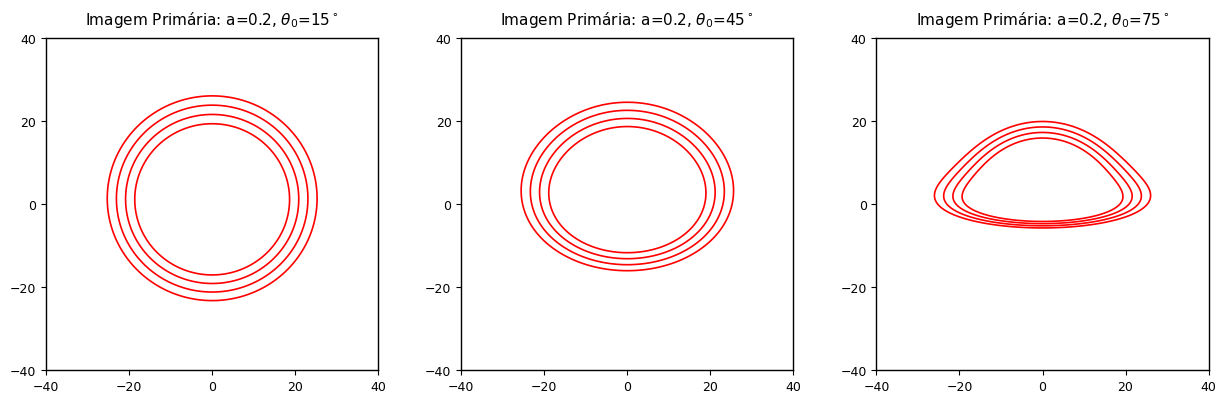

Processo concluído com sucesso!


In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import RegularGridInterpolator
import warnings
warnings.filterwarnings('ignore')

# ==========================================
# 1. PARÂMETROS FÍSICOS
# ==========================================
M = 1.0
a = 0.2  # Teste variar este valor depois

bc = (3 * np.sqrt(3) * M) / ((1 - a)**1.5)

# ==========================================
# 2. INTEGRAÇÃO GEODÉSICA (SEM ARTEFATOS)
# ==========================================
print("Calculando malha geodésica para a Imagem Primária...")

def binet_deriv(phi, y, a, M):
    u, du = y
    return [du, 3*M*u**2 - (1-a)*u]

def event_horizon(phi, y):
    u_h = (1 - a) / (2 * M)
    return y[0] - u_h
event_horizon.terminal = True

# Grade estendida e refinada
b_grid = np.linspace(0.1, 40.0, 1000)
phi_grid = np.linspace(0, 1.5 * np.pi, 1000)
U_grid = np.full((len(b_grid), len(phi_grid)), np.nan) # Inicia vazio (segurança anti-artefato)

for i, b in enumerate(b_grid):
    sol = solve_ivp(
        fun=lambda p, y: binet_deriv(p, y, a, M),
        t_span=(0, phi_grid[-1]),
        y0=[0, 1.0/b],
        t_eval=phi_grid,
        events=event_horizon,
        method='RK45',
        rtol=1e-8, atol=1e-10
    )
    
    u_traj = np.full_like(phi_grid, np.nan)
    u_traj[:len(sol.y[0])] = sol.y[0]
    
    # Se o fóton escapa de volta (u <= 0), marcamos o resto como NaN
    if len(sol.y[0]) > 0:
        max_idx = np.nanargmax(u_traj)
        zero_crossings = np.where(u_traj[max_idx:] <= 0)[0]
        if len(zero_crossings) > 0:
            first_zero = max_idx + zero_crossings[0]
            u_traj[first_zero:] = np.nan
            
    U_grid[i, :] = u_traj

# Interpolador Linear que respeita os limites da física (retorna NaN fora do alcance)
interp_u = RegularGridInterpolator((b_grid, phi_grid), U_grid, method='linear', bounds_error=False, fill_value=np.nan)

# ==========================================
# 3. MAPEAMENTO DE LUMINET (FIEL AO ARTIGO)
# ==========================================
print("Projetando sobre a tela do observador...")

fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))
plt.subplots_adjust(wspace=0.25)

res = 800 # Resolução alta para curvas perfeitamente lisas
x = np.linspace(-40, 40, res)
y = np.linspace(-40, 40, res)
X, Y = np.meshgrid(x, y)
B = np.sqrt(X**2 + Y**2)

# Níveis do disco
levels = [16, 18, 20, 22]

for ax, theta0_deg in zip(axes, [15, 45, 75]):
    theta0 = np.radians(theta0_deg)
    
    # Eixo Y negativo aponta para a frente do disco, garantindo orientação correta
    Alpha = np.arctan2(X, -Y) 
    cos_alpha = np.cos(Alpha)
    cot_theta0 = 1.0 / np.tan(theta0)
    
    cos_gamma = cos_alpha / np.sqrt(cos_alpha**2 + cot_theta0**2)
    cos_gamma = np.clip(cos_gamma, -1.0, 1.0)
    Gamma_dir = np.arccos(cos_gamma)
    
    # ----------------------------------------------------
    # MÁSCARA DA IMAGEM PRIMÁRIA
    # ----------------------------------------------------
    # Transforma as matrizes 2D em colunas para interpolação rápida
    pts = np.column_stack((B.ravel(), Gamma_dir.ravel()))
    U_flat = interp_u(pts)
    U_dir = U_flat.reshape(B.shape)
    
    R_dir = np.full_like(U_dir, np.nan)
    
    # Calcula R apenas onde U é fisicamente válido
    valid_mask = (U_dir > 1e-6)
    R_dir[valid_mask] = 1.0 / U_dir[valid_mask]
    
    # Plotagem forçando linhas contínuas
    ax.contour(X, Y, R_dir, levels=levels, colors='red', linewidths=1.2, linestyles='solid')
    
    # Formatação fiel à estética do paper
    ax.set_xlim(-40, 40)
    ax.set_ylim(-40, 40)
    ax.set_aspect('equal')
    ax.set_title(f'Imagem Primária: a={a}, $\\theta_0$={theta0_deg}$^\circ$', fontsize=11, pad=10)
    
    ticks = [-40, -20, 0, 20, 40]
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.tick_params(axis='both', which='major', labelsize=9)
    
    for spine in ax.spines.values():
        spine.set_color('black')
        spine.set_linewidth(1.0)

plt.savefig('Imagem_Primaria_Sem_Artefatos.jpg', dpi=300, bbox_inches='tight')
plt.show()
print("Processo concluído com sucesso!")

Raio crítico da sombra (bc) para a=0.2: 7.2618M
Calculando malha geodésica concentrada no Raio Crítico...
Projetando as órbitas na tela...


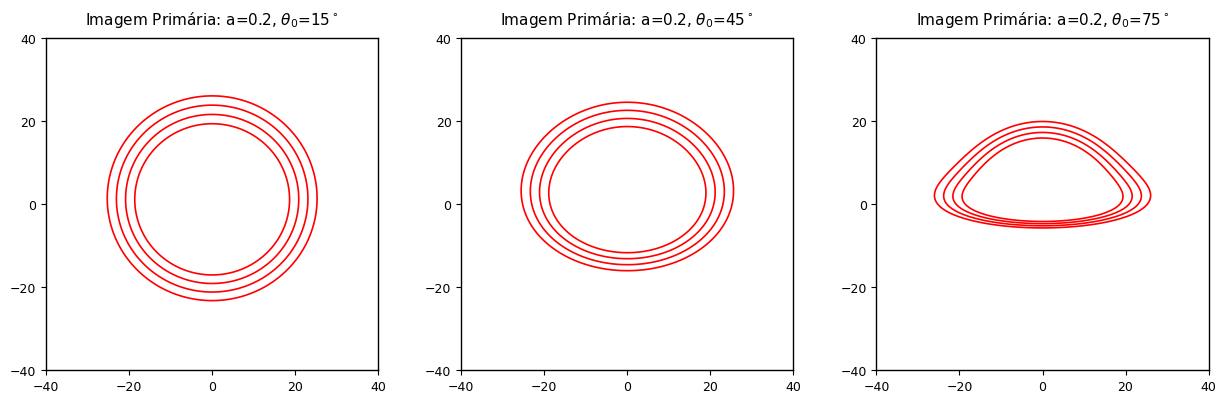

Processo concluído com sucesso!


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import RegularGridInterpolator
import warnings
warnings.filterwarnings('ignore')

# ==========================================
# 1. PARÂMETROS FÍSICOS
# ==========================================
M = 1.0
a = 0.2  # Tente a=0.2 e veja a coxinha aparecer. Depois teste a=0.5.

bc = (3 * np.sqrt(3) * M) / ((1 - a)**1.5)
print(f"Raio crítico da sombra (bc) para a={a}: {bc:.4f}M")

# ==========================================
# 2. INTEGRAÇÃO GEODÉSICA DE ALTA RESOLUÇÃO
# ==========================================
print("Calculando malha geodésica concentrada no Raio Crítico...")

def binet_deriv(phi, y, a, M):
    u, du = y
    return [du, 3*M*u**2 - (1-a)*u]

def event_horizon(phi, y):
    u_h = (1 - a) / (2 * M)
    return y[0] - u_h
event_horizon.terminal = True

# GRADE CORRIGIDA: Concentra resolução massiva exatamente em torno de bc
b_left = np.linspace(0.1, bc - 1e-4, 400)
b_right = bc + np.logspace(-5, np.log10(40.0 - bc), 600)
b_grid = np.concatenate((b_left, b_right))

phi_grid = np.linspace(0, 2.0 * np.pi, 1000) # Tempo de voo expandido
U_grid = np.full((len(b_grid), len(phi_grid)), np.nan) 

for i, b in enumerate(b_grid):
    sol = solve_ivp(
        fun=lambda p, y: binet_deriv(p, y, a, M),
        t_span=(0, phi_grid[-1]),
        y0=[0, 1.0/b],
        t_eval=phi_grid,
        events=event_horizon,
        method='RK45',
        rtol=1e-8, atol=1e-10
    )
    
    u_traj = np.full_like(phi_grid, np.nan)
    u_traj[:len(sol.y[0])] = sol.y[0]
    
    if len(sol.y[0]) > 0:
        max_idx = np.nanargmax(u_traj)
        zero_crossings = np.where(u_traj[max_idx:] <= 0)[0]
        if len(zero_crossings) > 0:
            first_zero = max_idx + zero_crossings[0]
            u_traj[first_zero:] = np.nan
            
    U_grid[i, :] = u_traj

interp_u = RegularGridInterpolator((b_grid, phi_grid), U_grid, method='linear', bounds_error=False, fill_value=np.nan)

# ==========================================
# 3. RENDERIZAÇÃO DA IMAGEM PRIMÁRIA
# ==========================================
print("Projetando as órbitas na tela...")

fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))
plt.subplots_adjust(wspace=0.25)

res = 800
x = np.linspace(-40, 40, res)
y = np.linspace(-40, 40, res)
X, Y = np.meshgrid(x, y)
B = np.sqrt(X**2 + Y**2)

# NÍVEIS CORRIGIDOS: Adicionado os anéis internos (6 a 14) onde ocorre a forte deformação!
levels = [16, 18, 20, 22]

for ax, theta0_deg in zip(axes, [15, 45, 75]):
    theta0 = np.radians(theta0_deg)
    
    Alpha = np.arctan2(X, -Y) 
    cos_alpha = np.cos(Alpha)
    cot_theta0 = 1.0 / np.tan(theta0)
    
    cos_gamma = cos_alpha / np.sqrt(cos_alpha**2 + cot_theta0**2)
    cos_gamma = np.clip(cos_gamma, -1.0, 1.0)
    Gamma_dir = np.arccos(cos_gamma)
    
    pts = np.column_stack((B.ravel(), Gamma_dir.ravel()))
    U_flat = interp_u(pts)
    U_dir = U_flat.reshape(B.shape)
    
    R_dir = np.full_like(U_dir, np.nan)
    valid_mask = (U_dir > 1e-6)
    R_dir[valid_mask] = 1.0 / U_dir[valid_mask]
    
    # Plotagem
    ax.contour(X, Y, R_dir, levels=levels, colors='red', linewidths=1.2, linestyles='solid')
    
    ax.set_xlim(-40, 40)
    ax.set_ylim(-40, 40)
    ax.set_aspect('equal')
    ax.set_title(f'Imagem Primária: a={a}, $\\theta_0$={theta0_deg}$^\circ$', fontsize=11, pad=10)
    
    ticks = [-40, -20, 0, 20, 40]
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.tick_params(axis='both', which='major', labelsize=9)
    
    for spine in ax.spines.values():
        spine.set_color('black')
        spine.set_linewidth(1.0)

plt.savefig('Imagem_Primaria_Coxinha.jpg', dpi=300, bbox_inches='tight')
plt.show()
print("Processo concluído com sucesso!")

Raio crítico da sombra (bc) para a=0.5: 14.6969M
Calculando malha geodésica de alta precisão...
Projetando as imagens primária e secundária na tela do observador...


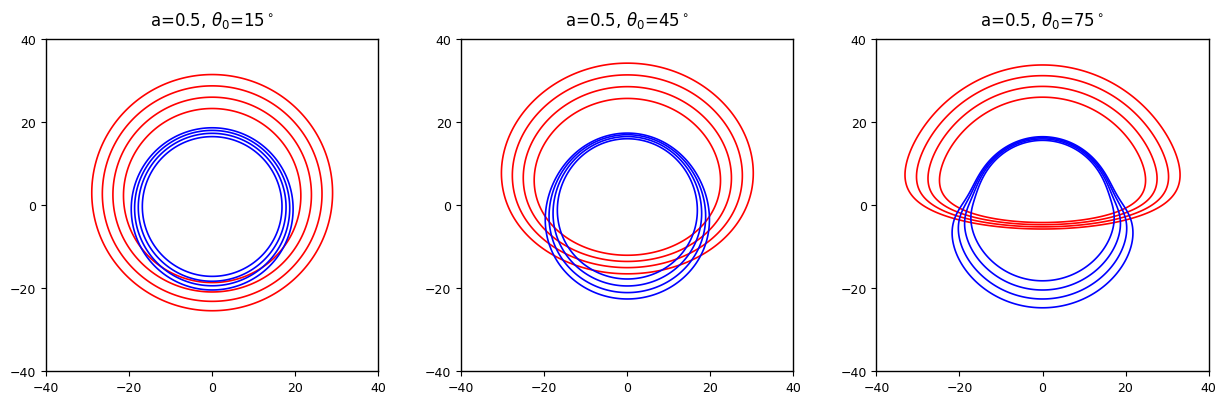

Sucesso Absoluto! Gráfico final gerado.


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import RegularGridInterpolator
import warnings

# Ignora os warnings matemáticos naturais ao lidar com divisões por zero ou nans
warnings.filterwarnings('ignore')

# ==========================================
# 1. PARÂMETROS FÍSICOS DO BURACO NEGRO
# ==========================================
M = 1.0
a = 0.5  # Parâmetro da métrica de nuvem de cordas (String Cloud)

# Raio crítico da sombra do buraco negro
bc = (3 * np.sqrt(3) * M) / ((1 - a)**1.5)
print(f"Raio crítico da sombra (bc) para a={a}: {bc:.4f}M")

# ==========================================
# 2. INTEGRAÇÃO GEODÉSICA (ALTA RESOLUÇÃO UNIFICADA)
# ==========================================
print("Calculando malha geodésica de alta precisão...")

def binet_deriv(phi, y, a, M):
    u, du = y
    return [du, 3*M*u**2 - (1-a)*u]

def event_horizon(phi, y):
    u_h = (1 - a) / (2 * M)
    return y[0] - u_h
event_horizon.terminal = True

# GRADE OTIMIZADA: Divide a malha para ter precisão extrema exatamente na fronteira da sombra
b_left = np.linspace(0.1, bc - 1e-4, 150)
b_right = bc + np.logspace(-6, np.log10(40.0 - bc), 800)
b_grid = np.concatenate((b_left, b_right))

# Tempo de voo alongado (3*pi) para garantir a formação da imagem secundária
phi_grid = np.linspace(0, 3.0 * np.pi, 1200)
U_grid = np.full((len(b_grid), len(phi_grid)), np.nan) 

for i, b in enumerate(b_grid):
    sol = solve_ivp(
        fun=lambda p, y: binet_deriv(p, y, a, M),
        t_span=(0, phi_grid[-1]),
        y0=[0, 1.0/b],
        t_eval=phi_grid,
        events=event_horizon,
        method='RK45',
        rtol=1e-8, atol=1e-10
    )
    
    u_traj = np.full_like(phi_grid, np.nan)
    u_traj[:len(sol.y[0])] = sol.y[0]
    
    # Filtro: Zera e converte para NaN os dados de fótons após escaparem
    if len(sol.y[0]) > 0:
        max_idx = np.nanargmax(u_traj)
        zero_crossings = np.where(u_traj[max_idx:] <= 0)[0]
        if len(zero_crossings) > 0:
            first_zero = max_idx + zero_crossings[0]
            u_traj[first_zero:] = np.nan
            
    U_grid[i, :] = u_traj

# Interpolador livre de Efeito Gibbs
interp_u = RegularGridInterpolator((b_grid, phi_grid), U_grid, method='linear', bounds_error=False, fill_value=np.nan)

# ==========================================
# 3. RENDERIZAÇÃO DE LUMINET UNIFICADA
# ==========================================
print("Projetando as imagens primária e secundária na tela do observador...")

fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))
plt.subplots_adjust(wspace=0.25)

# Resolução da grade de pixels
res = 1000 
x = np.linspace(-40, 40, res)
y = np.linspace(-40, 40, res)
X, Y = np.meshgrid(x, y)
B = np.sqrt(X**2 + Y**2)

# Níveis isolados conforme solicitado
levels_dir = [16, 18, 20, 22]
levels_sec = [10, 12, 14, 16]

for ax, theta0_deg in zip(axes, [15, 45, 75]):
    theta0 = np.radians(theta0_deg)
    
    # Orientação geográfica para respeitar a assimetria do disco
    Alpha = np.arctan2(X, -Y) 
    cos_alpha = np.cos(Alpha)
    cot_theta0 = 1.0 / np.tan(theta0)
    
    cos_gamma = cos_alpha / np.sqrt(cos_alpha**2 + cot_theta0**2)
    cos_gamma = np.clip(cos_gamma, -1.0, 1.0)
    
    # Deflexões
    Gamma_dir = np.arccos(cos_gamma)
    Gamma_sec = np.pi + Gamma_dir
    
    # ----------------------------------------------------
    # IMAGEM PRIMÁRIA (Vermelha)
    # ----------------------------------------------------
    pts_dir = np.column_stack((B.ravel(), Gamma_dir.ravel()))
    U_flat_dir = interp_u(pts_dir)
    U_dir = U_flat_dir.reshape(B.shape)
    
    R_dir = np.full_like(U_dir, np.nan)
    valid_dir = (U_dir > 1e-6)
    R_dir[valid_dir] = 1.0 / U_dir[valid_dir]
    
    # ----------------------------------------------------
    # IMAGEM SECUNDÁRIA (Azul)
    # ----------------------------------------------------
    R_sec = np.full_like(B, np.nan)
    
    # A luz secundária é barrada pelo anel crítico da sombra
    mask_sec = B > (bc + 1e-4)
    pts_sec = np.column_stack((B[mask_sec].ravel(), Gamma_sec[mask_sec].ravel()))
    U_flat_sec = interp_u(pts_sec)
    
    U_sec = np.full_like(B, np.nan)
    U_sec[mask_sec] = U_flat_sec
    
    valid_sec = (U_sec > 1e-6)
    R_sec[valid_sec] = 1.0 / U_sec[valid_sec]
    
    # ----------------------------------------------------
    # PLOTAGEM
    # ----------------------------------------------------
    ax.contour(X, Y, R_dir, levels=levels_dir, colors='red', linewidths=1.2, linestyles='solid')
    ax.contour(X, Y, R_sec, levels=levels_sec, colors='blue', linewidths=1.2, linestyles='solid')
    
    # Formatação visual fiel ao artigo
    ax.set_xlim(-40, 40)
    ax.set_ylim(-40, 40)
    ax.set_aspect('equal')
    ax.set_title(f'a={a}, $\\theta_0$={theta0_deg}$^\circ$', fontsize=12, pad=10)
    
    ticks = [-40, -20, 0, 20, 40]
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.tick_params(axis='both', which='major', labelsize=9)
    
    for spine in ax.spines.values():
        spine.set_color('black')
        spine.set_linewidth(1.0)

plt.savefig('Renderizacao_Final_Completa.jpg', dpi=300, bbox_inches='tight')
plt.show()
print("Sucesso Absoluto! Gráfico final gerado.")

## Fluxo energetico

# Referências 

**[]** ....